# Router Stage 2 -- Modality Classifier (CliniqAI)

**Task:** given an image already confirmed medical by Stage 1, which of your 7 modalities is it?

**Classes:** `brain_mri`, `kidney_ct`, `retinal`, `skin_lesion`, `pneumonia`, `breast_histology`,
`bone_fracture`

Trained only on medical images -- same 7 dataset folders as Stage 1's positive class, but now
each image is labeled by *which* modality it came from instead of a single `medical` label.

**Why this is an easy task:** fundus photos, CT slices, chest X-rays, dermoscopy images,
histology patches, and bone X-rays are visually very distinct domains -- expect 95-100%, similar
to your earlier 3-class flat router and Stage 1's near-perfect result.

**Config:** EfficientNet-B0, batch size 48, lr 1e-3, weight decay 1e-4, early stopping patience
10, 224x224 input, `num_workers=4` with `pin_memory` + `persistent_workers` + `cudnn.benchmark`
-- tuned after Stage 1 showed GPU utilization stuck at 40-50% with the original `num_workers=0`
/ batch 32 settings. Batch 48 (not 64) keeps VRAM usage inside your 4050's 6GB dedicated memory --
64 spilled into slow shared system memory during Stage 1 and made epochs slower despite 100%
utilization.


## 1. Session setup

In [1]:
import os
import sys

PROJECT_ROOT = r"E:\programming\CliniqAI"
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)

print("Working directory:", os.getcwd())

Working directory: E:\programming\CliniqAI


## 2. Configure dataset roots

**Check these paths before running.** To add `bone_fracture` later, add one line here --
everything else in this notebook adapts automatically since it reads `len(MODALITY_SOURCES)`
for the model's output size.

In [2]:
from pathlib import Path

# Modality name -> root folder (searched recursively). Add new entries here to extend.
MODALITY_SOURCES = {
    "brain_mri": Path("data/raw/brain_tumor"),
    "kidney_ct": Path("data/raw/kidney_stone"),
    "retinal": Path("data/raw/diabetic_retinopathy"),
    "skin_lesion": Path("data/raw/skin_lesion"),
    "pneumonia": Path("data/raw/pneumonia"),
    "breast_histology": Path("data/raw/breast_histology"),
    "bone_fracture": Path("data/raw/bone_fracture"),  # now trained and ready -- 7-class problem
}

for name, path in MODALITY_SOURCES.items():
    status = "OK" if path.exists() else "MISSING -- fix this path"
    print(f"  {name:<20} {str(path):<45} {status}")

CLASS_NAMES = sorted(MODALITY_SOURCES.keys())
print(f"\nClasses ({len(CLASS_NAMES)}): {CLASS_NAMES}")

  brain_mri            data\raw\brain_tumor                          OK
  kidney_ct            data\raw\kidney_stone                         OK
  retinal              data\raw\diabetic_retinopathy                 OK
  skin_lesion          data\raw\skin_lesion                          OK
  pneumonia            data\raw\pneumonia                            OK
  breast_histology     data\raw\breast_histology                     OK
  bone_fracture        data\raw\bone_fracture                        OK

Classes (7): ['bone_fracture', 'brain_mri', 'breast_histology', 'kidney_ct', 'pneumonia', 'retinal', 'skin_lesion']


## 3. Collect image paths per modality

Internal class/patient subfolder structure within each dataset is ignored -- every image under a
modality's root is pooled under that modality's single label.

**Includes corrupted-file validation** -- some datasets (bone_fracture in particular) contain a
handful of truncated/corrupted files that crash PIL mid-training. This checks only the sampled
subset actually collected here, not the full raw datasets, so it stays fast.

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
MAX_PER_CLASS = 4000  # caps large datasets (e.g. breast_histology) so no class dominates training
RANDOM_SEED = 42

import random
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True  # safety net for borderline-recoverable files
random.seed(RANDOM_SEED)

def is_valid_image(path: Path) -> bool:
    try:
        with Image.open(path) as img:
            img.load()  # forces a full decode -- this is what actually catches truncation
        return True
    except Exception:
        return False

def collect_images(root, max_count=None):
    if not root.exists():
        print(f"  [skip] {root} does not exist")
        return []
    files = [p for p in root.rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS]
    if max_count and len(files) > max_count:
        files = random.sample(files, max_count)
    return files

records = []
for modality, root in MODALITY_SOURCES.items():
    files = collect_images(root, MAX_PER_CLASS)
    valid_files = [f for f in files if is_valid_image(f)]
    n_bad = len(files) - len(valid_files)
    status = f"({n_bad} corrupted, skipped)" if n_bad else ""
    print(f"  {modality:<20} {len(valid_files)} images {status}")
    records.extend([(str(p), modality) for p in valid_files])

print(f"\nTotal images: {len(records)}")

  brain_mri            4000 images 
  kidney_ct            4000 images 
  retinal              3662 images 
  skin_lesion          4000 images 
  pneumonia            4000 images 
  breast_histology     4000 images 
  bone_fracture        4000 images 

Total images: 27662


## 4. Build dataframe and split (70/15/15, image-level)

Same reasoning as Stage 1 -- modality recognition doesn't need patient-level splitting.

In [4]:
import pandas as pd

df = pd.DataFrame(records, columns=["filepath", "label"])
df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

n = len(df)
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_df = df.iloc[:n_train].reset_index(drop=True)
val_df = df.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_df = df.iloc[n_train + n_val:].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print()
print(train_df["label"].value_counts())

Train: 19363  Val: 4149  Test: 4150

label
skin_lesion         2820
brain_mri           2804
kidney_ct           2790
breast_histology    2789
pneumonia           2785
bone_fracture       2776
retinal             2599
Name: count, dtype: int64


C:\Users\anish\AppData\Local\Temp\ipykernel_10964\618052461.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## 5. Dataset, transforms, dataloaders

**Performance note:** the Dataset class lives in `scripts/modality_dataset.py`, not defined
inline here -- required for `num_workers>0` to work on Windows (worker processes need to
`import` the class). Batch size is set to 48, not 64 -- 64 overflowed your 4050's 6GB VRAM into
slow shared system memory during Stage 1, which made epochs slower despite 100% GPU utilization
showing. 48 stays within dedicated VRAM while still meaningfully beating the original 32.

In [5]:
import sys
SCRIPTS_DIR = str(Path(PROJECT_ROOT) / "scripts")
if SCRIPTS_DIR not in sys.path:
    sys.path.insert(0, SCRIPTS_DIR)

from modality_dataset import ModalityDataset

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 48        # kept under VRAM limit -- 64 overflowed into shared memory on Stage 1
NUM_WORKERS = 4         # safe now since ModalityDataset is importable from its own module

label_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}
idx_to_label = {i: name for name, i in label_to_idx.items()}

for split_df in (train_df, val_df, test_df):
    split_df["label_idx"] = split_df["label"].map(label_to_idx)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = ModalityDataset(train_df, transform=train_transform)
val_dataset = ModalityDataset(val_df, transform=eval_transform)
test_dataset = ModalityDataset(test_df, transform=eval_transform)

loader_kwargs = dict(
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")
print("Class index mapping:", idx_to_label)

Batches -> train: 404, val: 87, test: 87
Class index mapping: {0: 'bone_fracture', 1: 'brain_mri', 2: 'breast_histology', 3: 'kidney_ct', 4: 'pneumonia', 5: 'retinal', 6: 'skin_lesion'}


## 6. Model -- EfficientNet-B0 (N-class head)

In [6]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

torch.backends.cudnn.benchmark = True  # fixed 224x224 input -- lets cuDNN pick faster kernels

NUM_CLASSES = len(CLASS_NAMES)

model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

Device: cuda


## 7. Training loop with early stopping (patience=10)

In [7]:
import time
from pathlib import Path

CHECKPOINT_DIR = Path("models/router")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "router_stage2_efficientnet_b0.pt"

NUM_EPOCHS = 20
PATIENCE = 10

best_val_loss = float("inf")
epochs_no_improve = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

def run_epoch(loader, train_mode):
    model.train() if train_mode else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    torch.set_grad_enabled(train_mode)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if train_mode:
            optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        if train_mode:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)
    scheduler.step(val_loss)
    elapsed = time.time() - start

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
          f"{elapsed:.1f}s")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch": epoch,
            "class_names": CLASS_NAMES,
        }, CHECKPOINT_PATH)
        print(f"  -> saved new best checkpoint (val_loss={val_loss:.4f})")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered after {epoch} epochs.")
            break

print("\nTraining complete. Best val_loss:", best_val_loss)

Epoch 01/20 | train_loss=0.0445 train_acc=0.9888 | val_loss=0.0063 val_acc=0.9988 | 133.2s
  -> saved new best checkpoint (val_loss=0.0063)
Epoch 02/20 | train_loss=0.0141 train_acc=0.9962 | val_loss=0.0012 val_acc=0.9995 | 105.4s
  -> saved new best checkpoint (val_loss=0.0012)
Epoch 03/20 | train_loss=0.0072 train_acc=0.9977 | val_loss=0.0038 val_acc=0.9988 | 104.4s
Epoch 04/20 | train_loss=0.0210 train_acc=0.9945 | val_loss=0.0031 val_acc=0.9993 | 106.0s
Epoch 05/20 | train_loss=0.0196 train_acc=0.9956 | val_loss=0.0077 val_acc=0.9976 | 105.3s
Epoch 06/20 | train_loss=0.0107 train_acc=0.9972 | val_loss=0.0063 val_acc=0.9981 | 107.0s
Epoch 07/20 | train_loss=0.0032 train_acc=0.9991 | val_loss=0.0006 val_acc=0.9998 | 106.2s
  -> saved new best checkpoint (val_loss=0.0006)
Epoch 08/20 | train_loss=0.0014 train_acc=0.9996 | val_loss=0.0033 val_acc=0.9993 | 105.2s
Epoch 09/20 | train_loss=0.0040 train_acc=0.9991 | val_loss=0.0013 val_acc=0.9998 | 100.5s
Epoch 10/20 | train_loss=0.0035 tr

## 8. Evaluate on test set

C:\Users\anish\AppData\Local\Temp\ipykernel_10964\502057721.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

Test accuracy: 1.0

                  precision    recall  f1-score   support

   bone_fracture       1.00      1.00      1.00       624
       brain_mri       1.00      1.00      1.00       582
breast_histology       1.00      1.00      1.00       621
       kidney_ct       1.00      1.00      1.00       608
       pneumonia       1.00      1.00      1.00       600
         retinal       1.00      1.00      1.00       538
     skin_lesion       1.00      1.00      1.00       577

        accuracy                           1.00      4150
       macro avg       1.00      1.00      1.00      4150
    weighted avg       1.00      1.00      1.00      4150



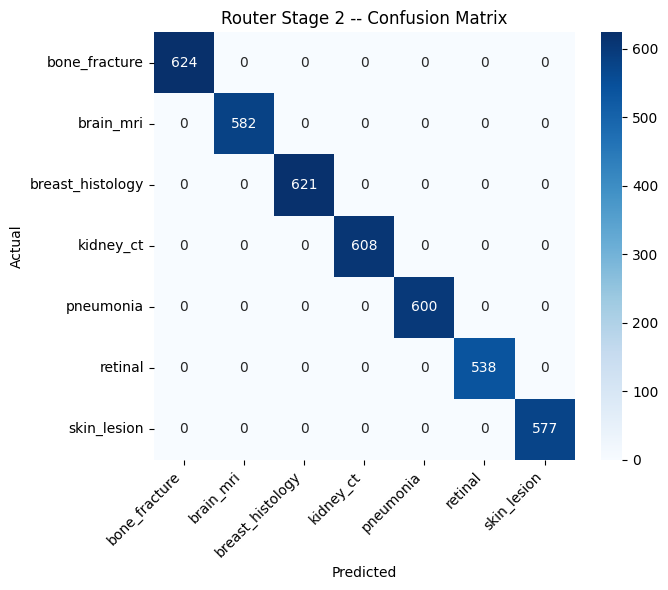

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test accuracy:", (np.array(all_preds) == np.array(all_labels)).mean())
print()
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Router Stage 2 -- Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Notes

- **Checkpoint:** `models/router/router_stage2_efficientnet_b0.pt` -- sync to Drive same as
  your specialists. `class_names` is saved inside the checkpoint so your backend's model registry
  can read the class order directly instead of hardcoding it.
- **Combined pipeline accuracy** is roughly Stage1_acc x Stage2_acc x Specialist_acc -- if each
  stage is genuinely 95%+, your end-to-end pipeline stays comfortably in a usable range even
  compounding three models' worth of error.
- **All 7 modalities are included** in this run, including `bone_fracture` -- if you want to
  verify or drop a class, edit `MODALITY_SOURCES` in cell 2 and rerun; the class count, model
  head size, and confusion matrix all adapt automatically.
- This checkpoint is what your backend's Stage 2 step loads to decide which specialist
  (`models/specialists/<modality>_*.pt`) to route an image to.
